# Manipulating Digital Images  

This notebook explores the basics of digital image processing in Python. We will learn how to load, display, and modify images using common libraries such as PIL.  

### **Objectives:**  
- Understand the structure of a digital image (pixels, color channels).  
- Load and display an image.
- Store an image using various formats.
- Apply basic transformations (resizing, rotation, grayscale conversion). 


In [26]:
from PIL import Image, ImageEnhance
from IPython.display import display
import numpy as np
import os

## Loading and Displaying Images

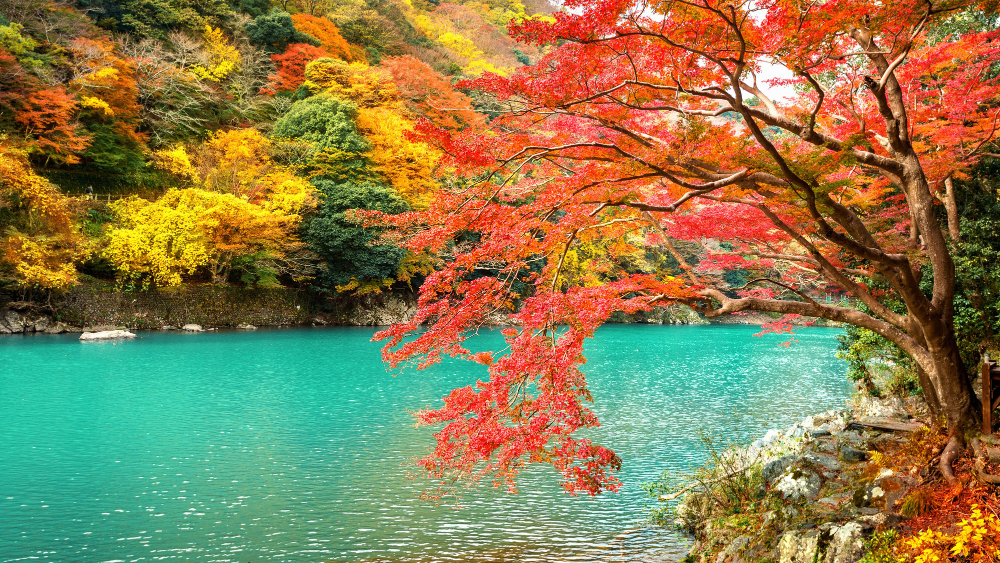

Image shape (H, W, C): (563, 1000, 3)
Image color mode: RGB
Image file size: 1077710 bytes


In [2]:
# Open the image
img = Image.open("data/autumn.jpg")

# Display the image inline
display(img)

# Convert image to a NumPy array
img_array = np.array(img)

# Display the shape of the image (height, width, channels)
print("Image shape (H, W, C):", img_array.shape)

# Display the image color mode (e.g., RGB, L, CMYK)
print("Image color mode:", img.mode)

# Get the file size of the image
size_jpg = os.path.getsize("data/autumn.jpg")

# Display the file size in bytes
print("Image file size:", size_jpg, "bytes")


## Comparing Image Formats: JPG, PNG, and TIFF

In [5]:
# Save the image in PNG format
img.save("data/winter_giants.png")

# Save the image in TIFF format
img.save("data/winter_giants.tiff")

print("Image saved in PNG and TIFF formats successfully.")

Image saved in PNG and TIFF formats successfully.


In [6]:
# Open the PNG image
img_png = Image.open("data/winter_giants.png")
size_png = os.path.getsize("data/winter_giants.png")

# Convert to NumPy array to get shape
img_png_array = np.array(img_png)

print("PNG Image:")
print("Shape:", img_png_array.shape)  # (Height, Width, Channels)
print("Color Mode:", img_png.mode)
print("Size:", size_png, "bytes\n")

# Open the TIFF image
img_tiff = Image.open("data/winter_giants.tiff")
size_tiff = os.path.getsize("data/winter_giants.tiff")

# Convert to NumPy array to get shape
img_tiff_array = np.array(img_tiff)

print("TIFF Image:")
print("Shape:", img_tiff_array.shape)  # (Height, Width, Channels)
print("Color Mode:", img_tiff.mode)
print("Size:", size_tiff, "bytes")


PNG Image:
Shape: (563, 1000, 3)
Color Mode: RGB
Size: 1411947 bytes

TIFF Image:
Shape: (563, 1000, 3)
Color Mode: RGB
Size: 1689608 bytes


### Comparison of Image Formats
- **JPEG/JPG**: Uses **lossy compression**, which reduces file size but may compromise image quality. Ideal for photographs and web images.
- **PNG**: Uses **lossless compression**, preserving image quality without sacrificing details. Supports transparency and is ideal for graphics and web use.
- **TIFF**: Uses **lossless compression** (or no compression), making it suitable for high-quality images and professional use (e.g., printing, archiving). TIFF files are typically larger than JPEG and PNG files.

## Manipulating Color and Grayscale Representations

R  |  B  |  G


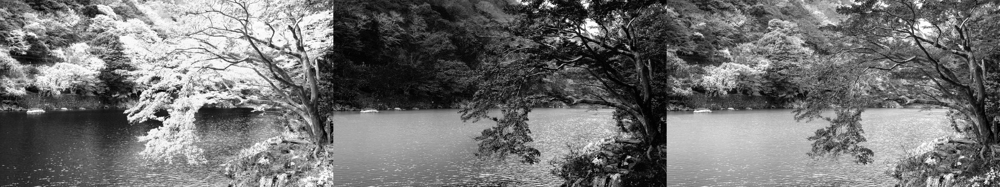

In [7]:
# Split the image into RGB channels
r, g, b = img_png.split()

# Create a new image to visualize the individual channels side by side
combined_img = Image.new('RGB', (r.width + b.width + g.width, max(r.height, b.height, g.height)))
combined_img.paste(r, (0, 0))
combined_img.paste(b, (r.width, 0))
combined_img.paste(g, (r.width + b.width, 0))

# Display the combined image
print("R  |  B  |  G")
display(combined_img)


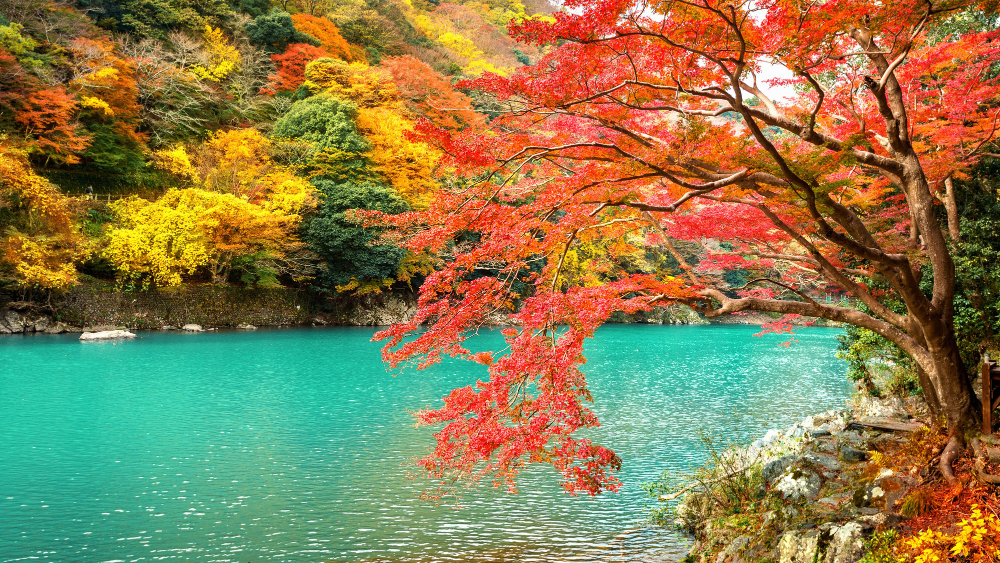

In [8]:
# Merge the RGB channels back into a single image
img_merged = Image.merge('RGB', (r, g, b))

# Display the reconstructed image
display(img_merged)

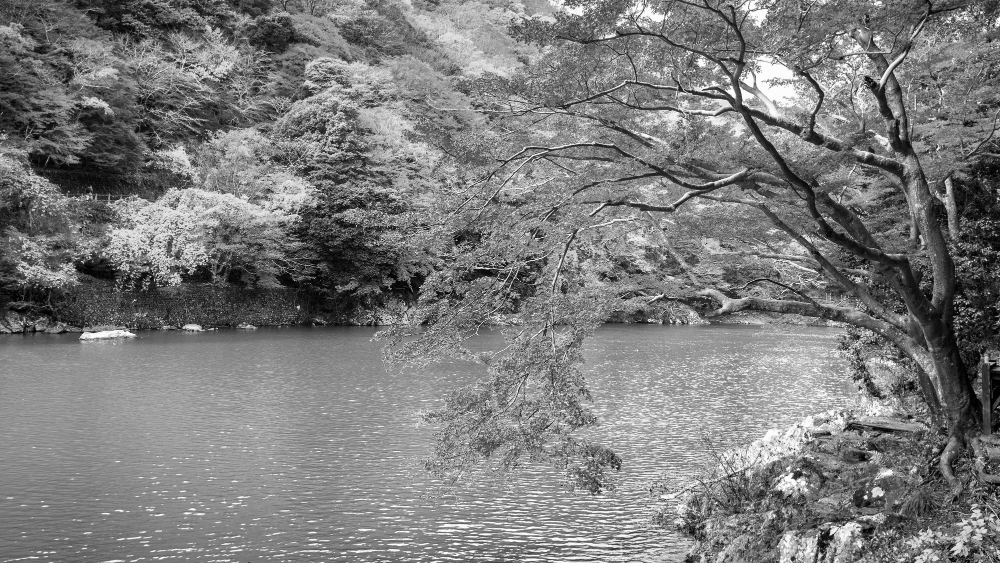

In [9]:
# Convert the image to grayscale
gray_img = img.convert('L')

# The 'L' mode represents luminance, which measures the brightness of each pixel.
# In grayscale images, pixel values range from 0 (black) to 255 (white).
# This conversion removes color information while preserving structural details.

# Display the grayscale image
display(gray_img)

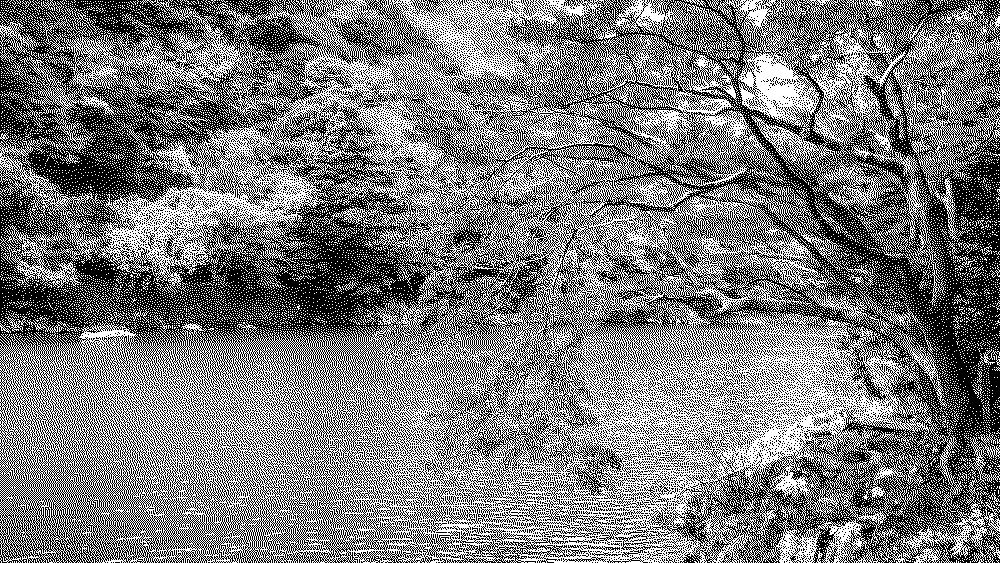

In [10]:
# Convert the image to binary (black and white)
binary_img = img.convert('1')

# The '1' mode represents a 1-bit image, where each pixel is either black (0) or white (1).
# This format is useful for thresholding operations, such as edge detection and document scanning.

# Display the binary image
display(binary_img)

## Image Transformations

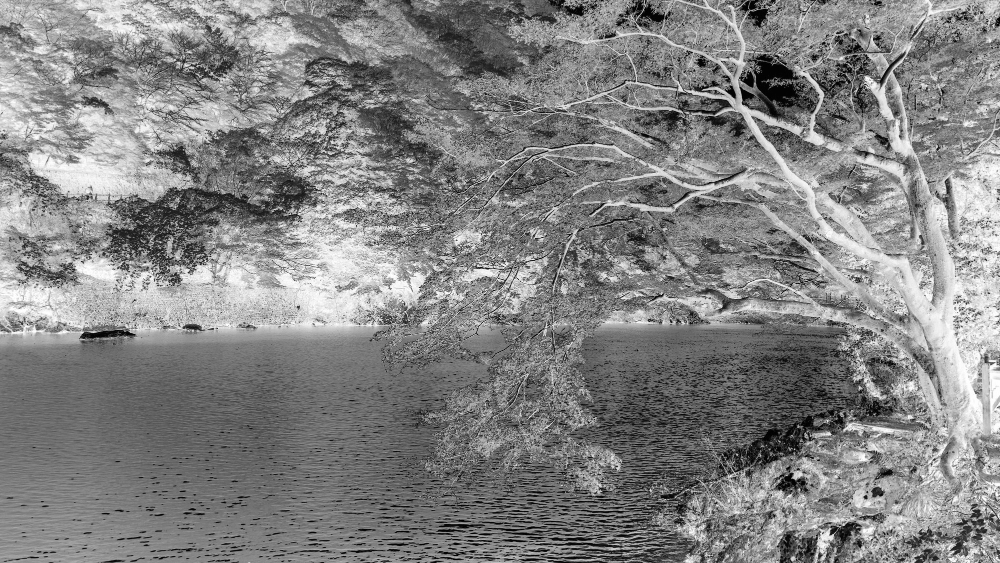

In [11]:
# Invert the grayscale image
max_value = 255
img_inverted = Image.eval(gray_img, lambda x: max_value - x)

# Image.eval applies a function to each pixel in the image.
# This operation subtracts each pixel value from 255, effectively inverting the grayscale image.
# Bright areas become dark, and dark areas become bright.

# Display the inverted image
display(img_inverted)

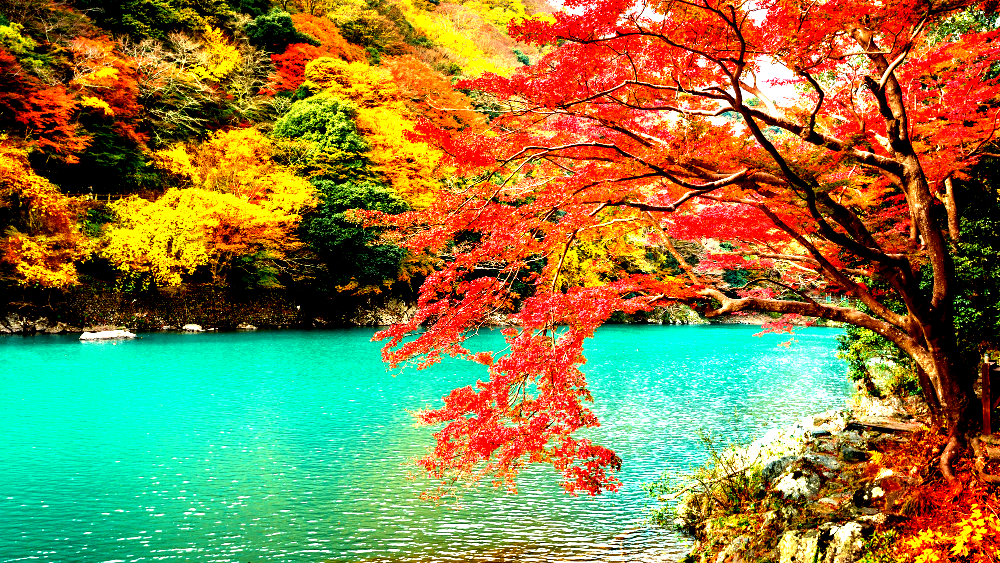

In [17]:
# Increase contrast (factor > 1 increases contrast, factor < 1 decreases it)
enhancer = ImageEnhance.Contrast(img)
high_contrast_img = enhancer.enhance(2.0)  # Double the contrast

# Display the high-contrast image
display(high_contrast_img)


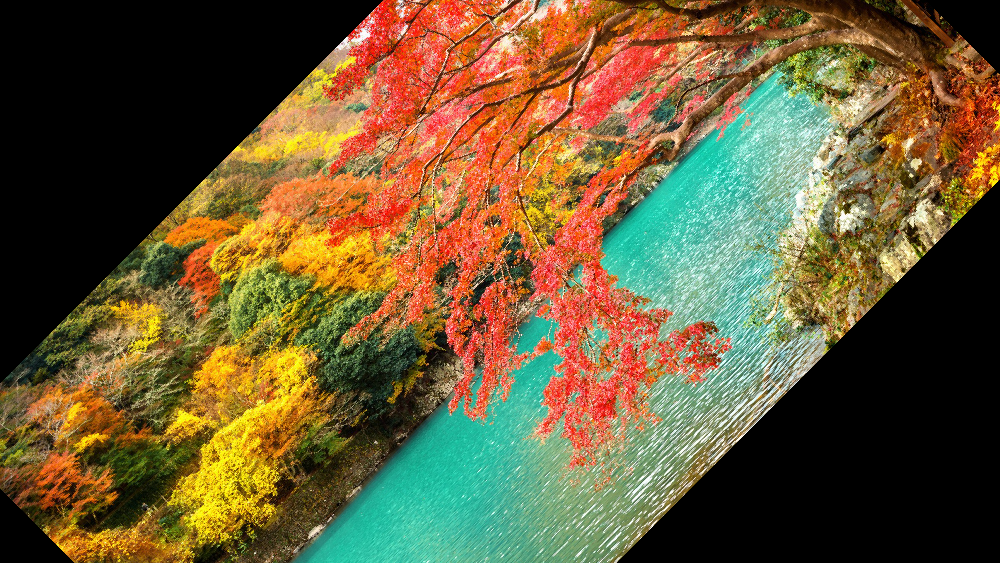

In [19]:
# Rotate the image by 45 degrees
rotated_img = img.rotate(45)

# Display the rotated image
display(rotated_img)

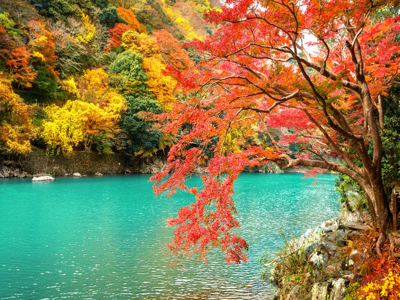

In [25]:
# Resize image to 400x300 pixels
resized_img = img.resize((400, 300))

# Display the resized image
display(resized_img)